# 03 · Choix et réglage des modèles

Quelle famille de modèles, puis quels paramètres pour CatBoost. Toutes les comparaisons utilisent les plis fixes du notebook 01.

1. Modèles de départ : régression logistique, XGBoost, CatBoost sur CPU et GPU, AutoGluon.
2. Ridge et forêt aléatoire avec des transformations numériques.
3. Réglage de CatBoost : taux d'apprentissage, profondeur, L2, échantillonnage.
4. Modes de calcul de CatBoost.

LightGBM et un réseau de neurones sont essayés en complément de CatBoost dans le notebook 05.

Les cinq notebooks : 01 données → 02 variables → 03 choix des modèles → 04 modèle final → 05 analyse des erreurs. Les CSV sont dans `data/`, les résultats dans `artifacts/<nom du notebook>/`.

In [1]:
# Environnement, chemins et fonctions partagés par les cinq notebooks
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def find_project_dir():
    candidates = []
    if os.environ.get('HMDA_PROJECT_DIR'):
        candidates.append(Path(os.environ['HMDA_PROJECT_DIR']))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis'))
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('Projet introuvable (data/train.csv et data/test.csv requis) ; définir HMDA_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                                        # CSV sources (lecture seule)
ARTIFACTS = PROJECT_DIR / 'artifacts'                                  # Résultats dans un sous-dossier par notebook
PREPARED_DIR = ARTIFACTS / '01_data_exploration'                       # 01 : données préparées et schéma fixe
FEATURE_DIR = ARTIFACTS / '02_feature_engineering' / 'feature_store'   # 02 : feature store
SEED = 42
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})


def ensure_catboost():
    """Installe et importe la version fixée de CatBoost pour le réentraînement."""
    global catboost
    try:
        installed = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('Une autre version de CatBoost est déjà chargée ; redémarrer puis relancer le notebook')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', f'catboost=={CATBOOST_VERSION}'])
        importlib.invalidate_caches()
    import catboost as catboost_module
    if catboost_module.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'CatBoost {CATBOOST_VERSION} requis ; version chargée : {catboost_module.__version__}')
    catboost = catboost_module
    return catboost_module


def ensure_gpu():
    """Vérifie la présence du GPU NVIDIA avant le réentraînement."""
    global GPU_NAME
    if shutil.which('nvidia-smi') is None:
        raise RuntimeError('GPU requis : choisir un GPU T4 dans le type de session Colab, puis relancer')
    probe = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           text=True, capture_output=True, check=False)
    if probe.returncode != 0 or not probe.stdout.strip():
        raise RuntimeError('GPU NVIDIA indisponible : choisir un T4 puis relancer')
    GPU_NAME = probe.stdout.strip().splitlines()[0]
    return GPU_NAME


print('Projet :', PROJECT_DIR.name)
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')

Projet : demandes-de-pret-immobilier-aux-etats-unis
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3


In [2]:
"""Identifiants de stockage historiques et libellés descriptifs.

Les valeurs assurent la reprise exacte des artefacts existants. Les paramètres,
les features et leur ordre sont définis dans les cellules métier.
Cette cellule est intégrée à chaque notebook : aucun import local requis.
"""

MODEL_DEPTH6_INITIAL = 'M0_C11_all'
MODEL_DEPTH6_ENRICHED = 'M1_C11_G7'
MODEL_DEPTH8_ENRICHED = 'M2_C7_G7'
MODEL_DEPTH6_REDUCED = 'M3_C11_lean'
FEATURE_SET_INITIAL = 'ROUND1_ALL'
FEATURE_SET_ENRICHED = 'G7'
FEATURE_SET_REDUCED = 'LEAN'
ENSEMBLE_THREE_MODELS_SEED42 = 'B13_seed42'
ENSEMBLE_MULTISEED = 'B_seeds'
ENSEMBLE_MULTISEED_PREFIX = 'B_seeds_'
ENSEMBLE_FULL_MULTISEED = 'full_Bseeds'
MODEL_INITIAL_POOL_LABEL = 'M0'
LEARNING_CURVE_SUBSET = 'LC_sub80'
LEARNING_CURVE_FULL = 'LC_full'
REDUCED_MODEL_CV_AUC = 'M3_in_13'
BASELINE_CATBOOST_DEPTH6 = 'CatBoost_R1'
BASELINE_CATBOOST_DEPTH8 = 'CatBoost_R2'
LIGHTGBM_LEAVES31 = 'L1_lgbm_leaves31'
LIGHTGBM_LEAVES127 = 'L2_lgbm_leaves127'
OBSERVED_LABELS_ONLY = 'A_base'
SOFT_PSEUDO_LABELS = 'A_pseudo'
LEARNING_CURVE_RUN_PATTERN = 'LC_*__fold?.json'
LEARNING_CURVE_FULL_PATTERN = 'LC_full__fold?.json'
REDUCED_MODEL_RUN_PATTERN = 'M3_C11_lean__fold?.json'
LIGHTGBM_RUN_PATTERN = 'L*_lgbm_*__fold?.json'
PSEUDO_LABEL_RUN_PATTERN = 'A_*__fold?.json'
FULL_ENSEMBLE_SUBMISSION = 'submission_full_Bseeds.csv'
ABLATION_ORIGINAL = 'F0_base'
ABLATION_ADD_DTI = 'F1_dti'
ABLATION_ADD_LTV = 'F2_ltv'
ABLATION_ADD_INCOME = 'F3_income'
ABLATION_ADD_MISSINGNESS = 'F4_missing'
ABLATION_ADD_GEOGRAPHIC_COUNTS = 'F5_freq'
ABLATION_INITIAL = 'F6_all'
ABLATION_INITIAL_REFERENCE = 'G0_all'
ABLATION_ADD_LTV_PRECISION = 'G1_precision'
ABLATION_ADD_LTV_THRESHOLDS = 'G2_thresholds'
ABLATION_ADD_IMPLIED_VALUE = 'G3_implied'
ABLATION_ADD_TERM = 'G4_term'
ABLATION_ENRICHED_WITH_COUNTS = 'G5_round2_all'
ABLATION_CORE_WITHOUT_COUNTS = 'G6_nofreq'
ABLATION_ENRICHED = 'G7_nofreq_round2_all'
ABLATION_ENRICHED_REFERENCE = 'H0_G7'
ABLATION_ADD_PRODUCT_FLAGS = 'H1_purpose'
ABLATION_ADD_LTV_CONSISTENCY = 'H2_ltv_consistency'
ABLATION_ADD_RISK_INTERACTIONS = 'H3_risk_layers'
ABLATION_ADD_TRACT_INCOME = 'H4_tract_income'
ABLATION_ALL_PRODUCT_RISK = 'H5_round3_all'
TUNING_DEPTH8_FIXED1600 = 'B0_R2_fixed1600'
TUNING_DEPTH8_LR005_L2_3 = 'C1_d8_lr05_l2_3_es'
TUNING_DEPTH6_LR003_L2_10 = 'C6_d6_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_10 = 'C3_d8_lr03_l2_10'
TUNING_DEPTH8_LR003_L2_3 = 'C2_d8_lr03_l2_3'
TUNING_DEPTH8_LR003_L2_30 = 'C4_d8_lr03_l2_30'
TUNING_DEPTH8_BERNOULLI80 = 'C7_d8_lr03_l2_10_sub80'
TUNING_DEPTH8_WITH_DTI = 'C8_d8_lr03_l2_10_DTI'
TUNING_DEPTH10_LR003_L2_10 = 'C5_d10_lr03_l2_10'
TUNING_DEPTH8_LR002_L2_10 = 'C9_d8_lr02_l2_10'
TUNING_DEPTH8_L2_30_BERNOULLI80 = 'C10_d8_lr03_l2_30_sub80'
TUNING_DEPTH6_BERNOULLI80 = 'C11_d6_lr03_l2_10_sub80'
TRAINING_STANDARD = 'V0_base'
TRAINING_ORDERED = 'V1_ordered'
TRAINING_NEWTON_SCORE = 'V2_newtonL2'
TRAINING_DEPTHWISE = 'V3_depthwise'
TRAINING_LOSSGUIDE = 'V4_lossguide'
TRAINING_POISSON = 'V5_poisson'
TRAINING_ROWS066 = 'V6_sub066'
TRAINING_BINS254 = 'V7_border254'
TRAINING_NO_CATEGORY_COMBINATIONS = 'V8_ctr1'
TRAINING_DROP_REDUNDANT_DEMOGRAPHICS = 'V9_drop_demo'
MEAN_GAIN_VS_SOURCE_FEATURES = 'mean_delta_vs_F0'
FOLDS_BETTER_THAN_SOURCE_FEATURES = 'folds_better_than_F0'
MEAN_GAIN_VS_INITIAL_FEATURES = 'mean_delta_vs_G0'
FOLDS_BETTER_THAN_INITIAL_FEATURES = 'folds_better_than_G0'
MEAN_GAIN_VS_ENRICHED_FEATURES = 'mean_delta_vs_H0'
FOLDS_BETTER_THAN_ENRICHED_FEATURES = 'folds_better_than_H0'
MEAN_GAIN_VS_FIXED_ITERATIONS = 'mean_delta_vs_B0'
FOLDS_BETTER_THAN_FIXED_ITERATIONS = 'folds_better_than_B0'
MEAN_GAIN_VS_STANDARD_BOOSTING = 'mean_delta_vs_V0'
FOLDS_BETTER_THAN_STANDARD_BOOSTING = 'folds_better_than_V0'
GAIN_VS_THREE_MODEL_ENSEMBLE = 'delta_vs_B13'
FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE = 'folds_better_than_B13'
TABM_ENSEMBLE_SUBMISSION_PREFIX = 'submission_Bseeds_TabM_w'
PURPOSE_ABLATION = 'feature block ablation, fast GPU CatBoost, paired vs F0_base'
PURPOSE_TRAINING_MODES = 'data-efficiency screen on M3 features; inner 15% early stop, score probe model on outer fold'
PURPOSE_TABM = 'TabM-mini (PyTorch) on G7 features; inner 15% early stop, no outer refit'
PURPOSE_FULL_REFIT = 'learning curve (80% vs 100% of outer-train) + full-data refit of M1-M3 x 3 seeds'

DISPLAY_LABELS = {
    MODEL_DEPTH6_INITIAL: 'CatBoost profondeur 6 · variables initiales',
    MODEL_DEPTH6_ENRICHED: 'CatBoost profondeur 6 · variables enrichies',
    MODEL_DEPTH8_ENRICHED: 'CatBoost profondeur 8 · variables enrichies',
    MODEL_DEPTH6_REDUCED: 'CatBoost profondeur 6 · variables réduites',
    FEATURE_SET_INITIAL: 'Variables initiales (68 colonnes)',
    FEATURE_SET_ENRICHED: 'Variables enrichies (72 colonnes)',
    FEATURE_SET_REDUCED: 'Variables réduites (68 colonnes)',
    ENSEMBLE_THREE_MODELS_SEED42: 'Ensemble de trois modèles · graine 42',
    ENSEMBLE_MULTISEED: 'Ensemble de trois modèles et trois graines',
    ENSEMBLE_MULTISEED_PREFIX: 'Ensemble multigraines · ',
    ENSEMBLE_FULL_MULTISEED: 'Ensemble multigraines sur toutes les données',
    MODEL_INITIAL_POOL_LABEL: 'CatBoost profondeur 6 · variables initiales',
    LEARNING_CURVE_SUBSET: 'Apprentissage sur 67 200 lignes',
    LEARNING_CURVE_FULL: 'Apprentissage sur 84 000 lignes',
    REDUCED_MODEL_CV_AUC: 'AUC du modèle réduit en validation croisée',
    BASELINE_CATBOOST_DEPTH6: 'CatBoost profondeur 6',
    BASELINE_CATBOOST_DEPTH8: 'CatBoost profondeur 8',
    LIGHTGBM_LEAVES31: 'LightGBM · 31 feuilles',
    LIGHTGBM_LEAVES127: 'LightGBM · 127 feuilles',
    OBSERVED_LABELS_ONLY: 'Cibles observées uniquement',
    SOFT_PSEUDO_LABELS: 'Pseudo-étiquettes souples',
    LEARNING_CURVE_RUN_PATTERN: 'Courbe d’apprentissage',
    LEARNING_CURVE_FULL_PATTERN: 'Courbe sur 84 000 lignes',
    REDUCED_MODEL_RUN_PATTERN: 'Validation croisée du modèle réduit',
    LIGHTGBM_RUN_PATTERN: 'Modèles LightGBM',
    PSEUDO_LABEL_RUN_PATTERN: 'Comparaison des pseudo-étiquettes',
    FULL_ENSEMBLE_SUBMISSION: 'Soumission de l’ensemble complet',
    ABLATION_ORIGINAL: 'Variables sources',
    ABLATION_ADD_DTI: 'Ajout des bornes DTI',
    ABLATION_ADD_LTV: 'Ajout de la cohérence LTV',
    ABLATION_ADD_INCOME: 'Ajout des ratios de revenu',
    ABLATION_ADD_MISSINGNESS: 'Ajout des valeurs manquantes',
    ABLATION_ADD_GEOGRAPHIC_COUNTS: 'Ajout des fréquences géographiques',
    ABLATION_INITIAL: 'Toutes les variables initiales',
    ABLATION_INITIAL_REFERENCE: 'Référence : variables initiales',
    ABLATION_ADD_LTV_PRECISION: 'Ajout de la précision LTV',
    ABLATION_ADD_LTV_THRESHOLDS: 'Ajout des seuils LTV',
    ABLATION_ADD_IMPLIED_VALUE: 'Ajout de la valeur immobilière implicite',
    ABLATION_ADD_TERM: 'Ajout des variables de durée',
    ABLATION_ENRICHED_WITH_COUNTS: 'Variables enrichies avec fréquences géographiques',
    ABLATION_CORE_WITHOUT_COUNTS: 'Variables initiales sans fréquences géographiques',
    ABLATION_ENRICHED: 'Variables enrichies sans fréquences géographiques',
    ABLATION_ENRICHED_REFERENCE: 'Référence : variables enrichies',
    ABLATION_ADD_PRODUCT_FLAGS: 'Ajout des indicateurs de produit',
    ABLATION_ADD_LTV_CONSISTENCY: 'Ajout de la cohérence des intervalles LTV',
    ABLATION_ADD_RISK_INTERACTIONS: 'Ajout des interactions de risque',
    ABLATION_ADD_TRACT_INCOME: 'Ajout du revenu relatif au secteur',
    ABLATION_ALL_PRODUCT_RISK: 'Ajout de tous les blocs produit et risque',
    TUNING_DEPTH8_FIXED1600: 'Profondeur 8 · 1 600 itérations fixes',
    TUNING_DEPTH8_LR005_L2_3: 'Profondeur 8 · taux 0.05 · L2=3',
    TUNING_DEPTH6_LR003_L2_10: 'Profondeur 6 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_10: 'Profondeur 8 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR003_L2_3: 'Profondeur 8 · taux 0.03 · L2=3',
    TUNING_DEPTH8_LR003_L2_30: 'Profondeur 8 · taux 0.03 · L2=30',
    TUNING_DEPTH8_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TUNING_DEPTH8_WITH_DTI: 'Profondeur 8 · taux 0.03 · L2=10 · bornes DTI',
    TUNING_DEPTH10_LR003_L2_10: 'Profondeur 10 · taux 0.03 · L2=10',
    TUNING_DEPTH8_LR002_L2_10: 'Profondeur 8 · taux 0.02 · L2=10',
    TUNING_DEPTH8_L2_30_BERNOULLI80: 'Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8',
    TUNING_DEPTH6_BERNOULLI80: 'Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8',
    TRAINING_STANDARD: 'Boosting standard',
    TRAINING_ORDERED: 'Boosting ordonné',
    TRAINING_NEWTON_SCORE: 'Score NewtonL2',
    TRAINING_DEPTHWISE: 'Croissance par profondeur',
    TRAINING_LOSSGUIDE: 'Croissance guidée par la perte',
    TRAINING_POISSON: 'Échantillonnage Poisson',
    TRAINING_ROWS066: 'Échantillonnage des lignes à 0.66',
    TRAINING_BINS254: '254 seuils numériques',
    TRAINING_NO_CATEGORY_COMBINATIONS: 'Sans combinaison de catégories',
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: 'Sans colonnes démographiques redondantes',
    MEAN_GAIN_VS_SOURCE_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_SOURCE_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_INITIAL_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_INITIAL_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_ENRICHED_FEATURES: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_ENRICHED_FEATURES: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_FIXED_ITERATIONS: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_FIXED_ITERATIONS: 'Plis meilleurs que la référence',
    MEAN_GAIN_VS_STANDARD_BOOSTING: 'Gain moyen face à la référence',
    FOLDS_BETTER_THAN_STANDARD_BOOSTING: 'Plis meilleurs que la référence',
    GAIN_VS_THREE_MODEL_ENSEMBLE: 'Gain face à l’ensemble de trois modèles',
    FOLDS_BETTER_THAN_THREE_MODEL_ENSEMBLE: 'Plis meilleurs que l’ensemble de trois modèles',
    TABM_ENSEMBLE_SUBMISSION_PREFIX: 'submission_Bseeds_TabM_w',
}

def semantic_label(value):
    """Décrit un identifiant historique pour l’affichage uniquement."""
    if not isinstance(value, str):
        return value
    # Un chemin affiché doit continuer à désigner le fichier réellement présent.
    if value.endswith(('.csv', '.json', '.parquet', '.npy')):
        return value
    if value in DISPLAY_LABELS:
        return DISPLAY_LABELS[value]
    for stored in sorted(DISPLAY_LABELS, key=len, reverse=True):
        value = value.replace(stored, DISPLAY_LABELS[stored])
    return value


def display_named(value, *args, **kwargs):
    """Affiche une copie : index, colonnes et libellés lisibles, calculs inchangés."""
    if isinstance(value, (pd.DataFrame, pd.Series)):
        value = value.copy(deep=True)
        if not isinstance(value.index, pd.MultiIndex):
            value.index = value.index.map(semantic_label)
        if isinstance(value, pd.DataFrame):
            value.columns = value.columns.map(semantic_label)
            for column in value.select_dtypes(include=['object', 'string']).columns:
                value[column] = value[column].map(semantic_label)
        elif value.dtype == object:
            value = value.map(semantic_label)
    display(value, *args, **kwargs)

**Entraînement.** Tous les boutons de `TRAIN` sont à `False` : les notebooks relisent les résultats sauvegardés dans `artifacts/`. Deux exceptions : le notebook 01 entraîne un petit modèle de contrôle sur CPU et le notebook 02 réécrit les variables. Pour refaire une expérience, mettre son bouton à `True` et choisir un **GPU T4** si le bloc le demande. Les modèles déjà entraînés sont sauvegardés et ne sont pas refaits.

In [3]:
TRAIN = {
    'baseline_cpu': False,   # Baselines CatBoost de profondeur 6/8 sur CPU (environ 3 h sur Colab)
    'tuning': False,         # Réglage CatBoost sur cinq folds (GPU, environ 2,5 h)
    'screen': False,         # Sélection des modes de calcul (GPU, environ 2 h)
}

## 0. Chargement des données et des variables

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


manifest_path = PREPARED_DIR / 'manifest.json'
schema_path = PREPARED_DIR / 'schema.json'
if not manifest_path.is_file() or not schema_path.is_file():
    raise FileNotFoundError(
        f'Fichier manquant : {manifest_path} ou {schema_path} ; exécuter d’abord 01_data_exploration.ipynb'
    )
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
schema = json.loads(schema_path.read_text(encoding='utf-8'))
require(manifest['schema_version'] == schema['schema_version'] == '1.0', 'Version du contrat de données incompatible')
require(manifest['seed'] == SEED and manifest['n_splits'] == 5, 'Configuration des cinq folds incompatible')
require(set(manifest['source_files']) == {'train.csv', 'test.csv', 'sample_submission.csv'},
        'Liste des fichiers source incomplète')
expected_prepared = {
    'train_features.csv', 'test_features.csv', 'train_labels.csv',
    'test_ids.csv', 'folds.csv', 'audit.csv', 'schema.json',
}
require(set(manifest['output_files']) == expected_prepared, 'Liste des fichiers préparés incomplète')
for name, info in manifest['source_files'].items():
    path = DATA_DIR / name
    require(path.is_file(), f'Données source manquantes : {path}')
    require(sha256_file(path) == info['sha256'], f'Fichier source modifié : {name} ; réexécuter 01')
for name, info in manifest['output_files'].items():
    path = PREPARED_DIR / name
    require(path.is_file(), f'Fichier préparé manquant : {path}')
    require(sha256_file(path) == info['sha256'], f'Empreinte du fichier préparé différente : {name} ; réexécuter 01')

FEATURE_COLUMNS = schema['feature_columns']
NUMERIC_COLUMNS = schema['numeric_columns']
CATEGORICAL_COLUMNS = schema['categorical_columns']
require(len(FEATURE_COLUMNS) == 56 and len(NUMERIC_COLUMNS) == 13
        and len(CATEGORICAL_COLUMNS) == 43, '56 colonnes attendues : 13 numériques, 43 catégorielles')
require(set(FEATURE_COLUMNS) == set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS),
        'Répartition numérique/catégorielle incomplète')
require(not {'id', 'accepted'} & set(FEATURE_COLUMNS), 'Les ID et la cible ne peuvent pas servir de variables')


def read_features(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    require(frame.columns.tolist() == FEATURE_COLUMNS, f'Variables ou ordre des colonnes incompatibles : {path.name}')
    for column in NUMERIC_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column].replace('', np.nan), errors='raise',
        ).astype('float64')
    require(not np.isinf(frame[NUMERIC_COLUMNS].to_numpy()).any(), 'Valeurs infinies dans les colonnes numériques')
    require(not frame[CATEGORICAL_COLUMNS].eq('').any().any(), 'Chaînes vides dans les colonnes catégorielles')
    return frame


X_base = read_features(PREPARED_DIR / 'train_features.csv')
X_test_base = read_features(PREPARED_DIR / 'test_features.csv')
labels = pd.read_csv(PREPARED_DIR / 'train_labels.csv', dtype=str, keep_default_na=False)
test_id_frame = pd.read_csv(PREPARED_DIR / 'test_ids.csv', dtype=str, keep_default_na=False)
fold_frame = pd.read_csv(PREPARED_DIR / 'folds.csv', dtype=str, keep_default_na=False)
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv', dtype=str, keep_default_na=False)

require(labels.columns.tolist() == ['id', 'accepted'], 'Colonnes des cibles train incompatibles')
require(test_id_frame.columns.tolist() == ['id'], 'Colonnes des ID test incompatibles')
require(fold_frame.columns.tolist() == ['id', 'fold'], 'Colonnes du fichier de folds incompatibles')
require(sample_submission.columns.tolist() == ['id', 'accepted'], 'Colonnes du modèle de soumission incompatibles')
require(len(X_base) == len(labels) == len(fold_frame) == 105000, 'Nombre de lignes train incorrect')
require(len(X_test_base) == len(test_id_frame) == len(sample_submission) == 45000,
        'Nombre de lignes test incorrect')

train_ids = labels['id']
test_ids = test_id_frame['id']
require(train_ids.is_unique and test_ids.is_unique, 'ID en double')
require(train_ids.ne('').all() and test_ids.ne('').all(), 'ID vide')
require(train_ids.equals(fold_frame['id']), 'ID des folds désalignés avec le train')
require(test_ids.equals(sample_submission['id']), 'Ordre des ID test différent du modèle de soumission')
require(set(train_ids).isdisjoint(test_ids), 'ID communs au train et au test')
require(set(labels['accepted']) == {'0', '1'}, 'accepted doit contenir les deux valeurs 0 et 1')
raw_train_identity = pd.read_csv(
    DATA_DIR / 'train.csv', usecols=['id', 'accepted'],
    dtype=str, keep_default_na=False,
)
raw_test_identity = pd.read_csv(
    DATA_DIR / 'test.csv', usecols=['id'], dtype=str, keep_default_na=False,
)
require(train_ids.equals(raw_train_identity['id'])
        and labels['accepted'].equals(raw_train_identity['accepted']),
        'ID ou cibles préparés différents du train.csv initial')
require(test_ids.equals(raw_test_identity['id']),
        'ID test préparés différents du test.csv initial')
y = labels['accepted'].astype('int8')
require(set(fold_frame['fold']) == {'1', '2', '3', '4', '5'}, 'Les folds doivent être numérotés de 1 à 5')
fold_assignment = fold_frame['fold'].astype('int8').to_numpy()

expected_folds = np.zeros(len(X_base), dtype=np.int8)
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, valid_index) in enumerate(splitter.split(X_base, y), start=1):
    expected_folds[valid_index] = fold
require(np.array_equal(fold_assignment, expected_folds), 'Les folds ne correspondent pas au découpage fixe avec seed=42')
DATA_HASHES = {
    'manifest.json': sha256_file(manifest_path),
    **{name: info['sha256'] for name, info in manifest['output_files'].items()},
}
print(f'Données vérifiées : train {len(X_base):,}, test {len(X_test_base):,}, 56 variables initiales.')
display_named(pd.crosstab(fold_assignment, y, rownames=['fold'], colnames=['accepted']))

def checked_probabilities(model, features):
    require(list(model.classes_) == [0, 1], 'Ordre des classes différent de [0, 1]')
    probability = np.asarray(model.predict_proba(features)[:, 1], dtype=float)
    require(probability.ndim == 1 and len(probability) == len(features)
            and np.isfinite(probability).all()
            and ((probability >= 0) & (probability <= 1)).all(),
            'Probabilités prédites invalides')
    return probability


def write_json(path, payload):
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(path)


def fixed_config(output_dir, config):
    """Écrire la configuration au premier passage, puis exiger son identité pour ne pas mélanger les expériences."""
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / 'config.json'
    if path.is_file():
        saved = json.loads(path.read_text(encoding='utf-8'))
        require(saved == config,
                f'{output_dir.name} contient des résultats avec une autre configuration ; changer EXPERIMENT_ID')
    else:
        write_json(path, config)

Données vérifiées : train 105,000, test 45,000, 56 variables initiales.


accepted,0,1
fold,,
1,3151,17849
2,3151,17849
3,3151,17849
4,3151,17849
5,3152,17848


In [5]:
# Charge les features produites par 02, nécessaires au réentraînement.
def load_feature_store():
    meta_path = FEATURE_DIR / 'feature_store.json'
    require(meta_path.is_file(), 'Feature store absent : exécuter 02_feature_engineering.ipynb')
    meta = json.loads(meta_path.read_text(encoding='utf-8'))
    require(meta['data_hashes'] == DATA_HASHES, 'Feature store incompatible avec les données de 01 : relancer 02')
    stores = {}
    for part, expected_rows in [('train', len(X_base)), ('test', len(X_test_base))]:
        path = FEATURE_DIR / f'blocks_{part}.parquet'
        require(sha256_file(path) == meta['files'][path.name], f'SHA-256 incorrect pour {path.name} : relancer 02')
        frame = pd.read_parquet(path)
        require(len(frame) == expected_rows, f'Nombre de lignes incorrect : {path.name}')
        for column in frame.columns:
            frame[column] = frame[column].astype(object if column in meta['categorical'] else 'float64')
        stores[part] = frame
    blocks = {name: (stores['train'][cols].reset_index(drop=True), stores['test'][cols].reset_index(drop=True))
              for name, cols in meta['blocks'].items()}
    return blocks, set(meta['categorical']), meta


def variant_frames(blocks):
    """Ajoute les blocs choisis aux 56 colonnes sources, comme dans 02."""
    train_parts = [X_base] + [BLOCKS[b][0] for b in blocks]
    test_parts = [X_test_base] + [BLOCKS[b][1] for b in blocks]
    train = pd.concat(train_parts, axis=1)
    test = pd.concat(test_parts, axis=1)
    require(train.columns.is_unique and train.columns.equals(test.columns), 'Colonnes incohérentes entre les variantes train/test')
    require(train.iloc[:, :len(FEATURE_COLUMNS)].equals(X_base), 'Les 56 colonnes sources ont été modifiées')
    cats = CATEGORICAL_COLUMNS + [c for c in train.columns if c in NEW_CATEGORICAL]
    return train, test, cats


if (FEATURE_DIR / 'feature_store.json').is_file():
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = load_feature_store()
    print(f"Feature store : {len(BLOCKS)} blocs, {sum(len(c) for c in FEATURE_META['blocks'].values())} colonnes ; "
          f"jeux de features {[semantic_label(name) for name in FEATURE_META['feature_sets']]}")
else:
    BLOCKS, NEW_CATEGORICAL, FEATURE_META = None, set(), None
    print('Feature store absent : lecture des résultats possible ; exécuter 02 avant le réentraînement.')

Feature store : 13 blocs, 25 colonnes ; jeux de features ['Variables initiales (68 colonnes)', 'Variables enrichies (72 colonnes)', 'Variables réduites (68 colonnes)']


In [6]:
# Lit les résultats JSON par modèle et fold pour des comparaisons appariées.
def load_runs(directory, pattern='*__fold?.json'):
    directory = Path(directory)
    paths = sorted(directory.glob(pattern))
    require(paths, f'Aucun résultat dans {directory} : synchroniser artifacts depuis Drive ou activer le réentraînement')
    return pd.DataFrame([json.loads(p.read_text(encoding='utf-8')) for p in paths])


def paired_table(runs, key, baseline, min_gain=0.0005, min_folds=4):
    auc = runs.pivot(index='fold', columns=key, values='valid_auc')
    require(baseline in auc.columns, f'Référence absente : {baseline}')
    delta = auc.sub(auc[baseline], axis=0)
    table = pd.DataFrame({
        'folds': auc.notna().sum(),
        'mean_auc': auc.mean(),
        'delta_vs_base': delta.mean(),
        'folds_better': (delta > 0).sum(),
    })
    table['keep'] = ((table['folds'] == 5) & (table['delta_vs_base'] >= min_gain)
                     & (table['folds_better'] >= min_folds))
    table.loc[baseline, 'keep'] = False
    return table.sort_values('mean_auc', ascending=False), delta


def plot_deltas(delta, baseline, title):
    others = delta.drop(columns=[baseline])
    order = others.mean().sort_values().index.tolist()
    means = others[order].mean() * 1e4
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.6))
    ax.barh(range(len(order)), means, color=['#4c72b0' if v > 0 else '#c44e52' for v in means])
    for i, name in enumerate(order):
        ax.scatter(others[name] * 1e4, np.full(len(others), i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(range(len(order)), [semantic_label(name) for name in order])
    ax.set_xlabel(f'Écart AUC / {semantic_label(baseline)} (×1e-4) ; barre = moyenne, points = folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 1. Modèles de départ

| Modèle | Réglage |
|---|---|
| Régression logistique | géographie simplifiée, interaction DTI × type de prêt, indicateurs de LTV extrême ; imputation et standardisation ajustées dans chaque pli |
| XGBoost | catégories natives, profondeur 6, early stopping dans le pli |
| CatBoost profondeur 6 et 8 | 56 colonnes d'origine, taux 0.05, L2 = 3, 1 600 itérations |

CatBoost est nettement devant. Avec les mêmes paramètres affichés, la version GPU fait environ 0.001 de moins que la version CPU ; la section 3 montre que cela vient de l'échantillonnage par défaut, qui n'est pas le même. Le code de la régression logistique et de XGBoost date de nos premiers notebooks (premier commit du dépôt) ; le bloc ci-dessous permet de réentraîner les CatBoost.

In [7]:
cpu_run = ARTIFACTS / '03_model_selection' / 'baseline_catboost_xgboost'   # CatBoost de profondeur 6/8, XGBoost (CPU)
lr_run = ARTIFACTS / '03_model_selection' / 'baseline_logistic'            # Régression logistique
rows = []
for path in [cpu_run / 'summary.csv', lr_run / 'summary.csv', cpu_run / 'blend_summary.csv']:
    for r in pd.read_csv(path).itertuples():
        rows.append({'Modèle': r.model, 'AUC sur cinq folds': r.mean_fold_auc, 'Écart-type': r.std_fold_auc,
                     'OOF LogLoss': r.pooled_oof_logloss})
rows.append({'Modèle': 'CatBoost profondeur 8 (GPU T4, mêmes paramètres)', 'AUC sur cinq folds': 0.91498, 'Écart-type': np.nan, 'OOF LogLoss': np.nan})
display_named(pd.DataFrame(rows).sort_values('AUC sur cinq folds', ascending=False).reset_index(drop=True).round(5))

,Modèle,AUC sur cinq folds,Écart-type,OOF LogLoss
0,Blend_R1_R2_50,0.91608,0.00564,0.19869
1,CatBoost profondeur 8,0.91604,0.00547,0.19855
2,Blend_R2_XGB_90_10,0.91588,0.00563,0.19923
3,CatBoost profondeur 6,0.91507,0.00577,0.19998
4,"CatBoost profondeur 8 (GPU T4, mêmes paramètres)",0.91498,NaN,NaN
5,LR,0.90020,0.00592,0.22406
6,XGBoost,0.89284,0.00595,0.23018


In [8]:
if TRAIN['baseline_cpu']:
    ensure_catboost()
    # Réentraîne CatBoost de profondeur 6/8 sur CPU (1600 itérations) dans un dossier distinct.
    RERUN_DIR = ARTIFACTS / '03_model_selection' / 'baseline_catboost_rerun'
    RERUN_DIR.mkdir(parents=True, exist_ok=True)
    base_params = dict(iterations=1600, learning_rate=0.05, l2_leaf_reg=3.0, loss_function='Logloss',
                       eval_metric='AUC', nan_mode='Min', random_seed=SEED, task_type='CPU',
                       thread_count=os.cpu_count() or 2, use_best_model=False,
                       allow_writing_files=False, verbose=False)
    rerun_rows = []
    for fold in range(1, 6):
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        for name, depth in [(BASELINE_CATBOOST_DEPTH6, 6), (BASELINE_CATBOOST_DEPTH8, 8)]:
            path = RERUN_DIR / f'{name}__fold{fold}.json'
            if path.is_file():
                rerun_rows.append(json.loads(path.read_text(encoding='utf-8')))
                continue
            started = time.perf_counter()
            model = catboost.CatBoostClassifier(**base_params, depth=depth)
            model.fit(X_base.iloc[fit_idx], y.iloc[fit_idx], cat_features=CATEGORICAL_COLUMNS)
            probability = checked_probabilities(model, X_base.iloc[valid_idx])
            row = {'model': name, 'fold': fold, 'valid_auc': roc_auc_score(y.iloc[valid_idx], probability),
                   'seconds': time.perf_counter() - started}
            write_json(path, row)
            rerun_rows.append(row)
            print(f"{name} fold {fold}: AUC={row['valid_auc']:.6f}  {row['seconds'] / 60:.1f} min", flush=True)
    display_named(pd.DataFrame(rerun_rows).pivot(index='fold', columns='model', values='valid_auc').agg(['mean', 'std']).round(6))
else:
    print("Bloc désactivé (TRAIN['baseline_cpu'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['baseline_cpu'] = False) ; affichage des résultats enregistrés dans artifacts/.


**AutoGluon** (`extreme_quality`, GPU T4, 40 minutes, pli 1) : 0.8996. TabICL et TabDPT ont manqué de mémoire et seul un LightGBM a été entraîné, donc cet essai dit surtout que nos ressources ne suffisaient pas.

## 2. Ridge, forêt aléatoire et transformations

Six représentations des variables numériques sont essayées avec Ridge et une forêt aléatoire : valeurs brutes, polynômes de degré 2 et 3, quantiles, approximation RBF, splines ; les catégories sont en one-hot. Ridge gagne au mieux 0.003, la forêt rien. Les deux restent très loin de CatBoost (environ 0.916). Ce code date aussi de nos premiers notebooks.

model,RandomForest,Ridge
representation,,
base,0.88978,0.88186
poly2,0.88848,0.88340
poly3,0.88014,0.88217
quantile,0.88979,0.88491
rbf,0.87905,0.88385
spline,0.88983,0.88492


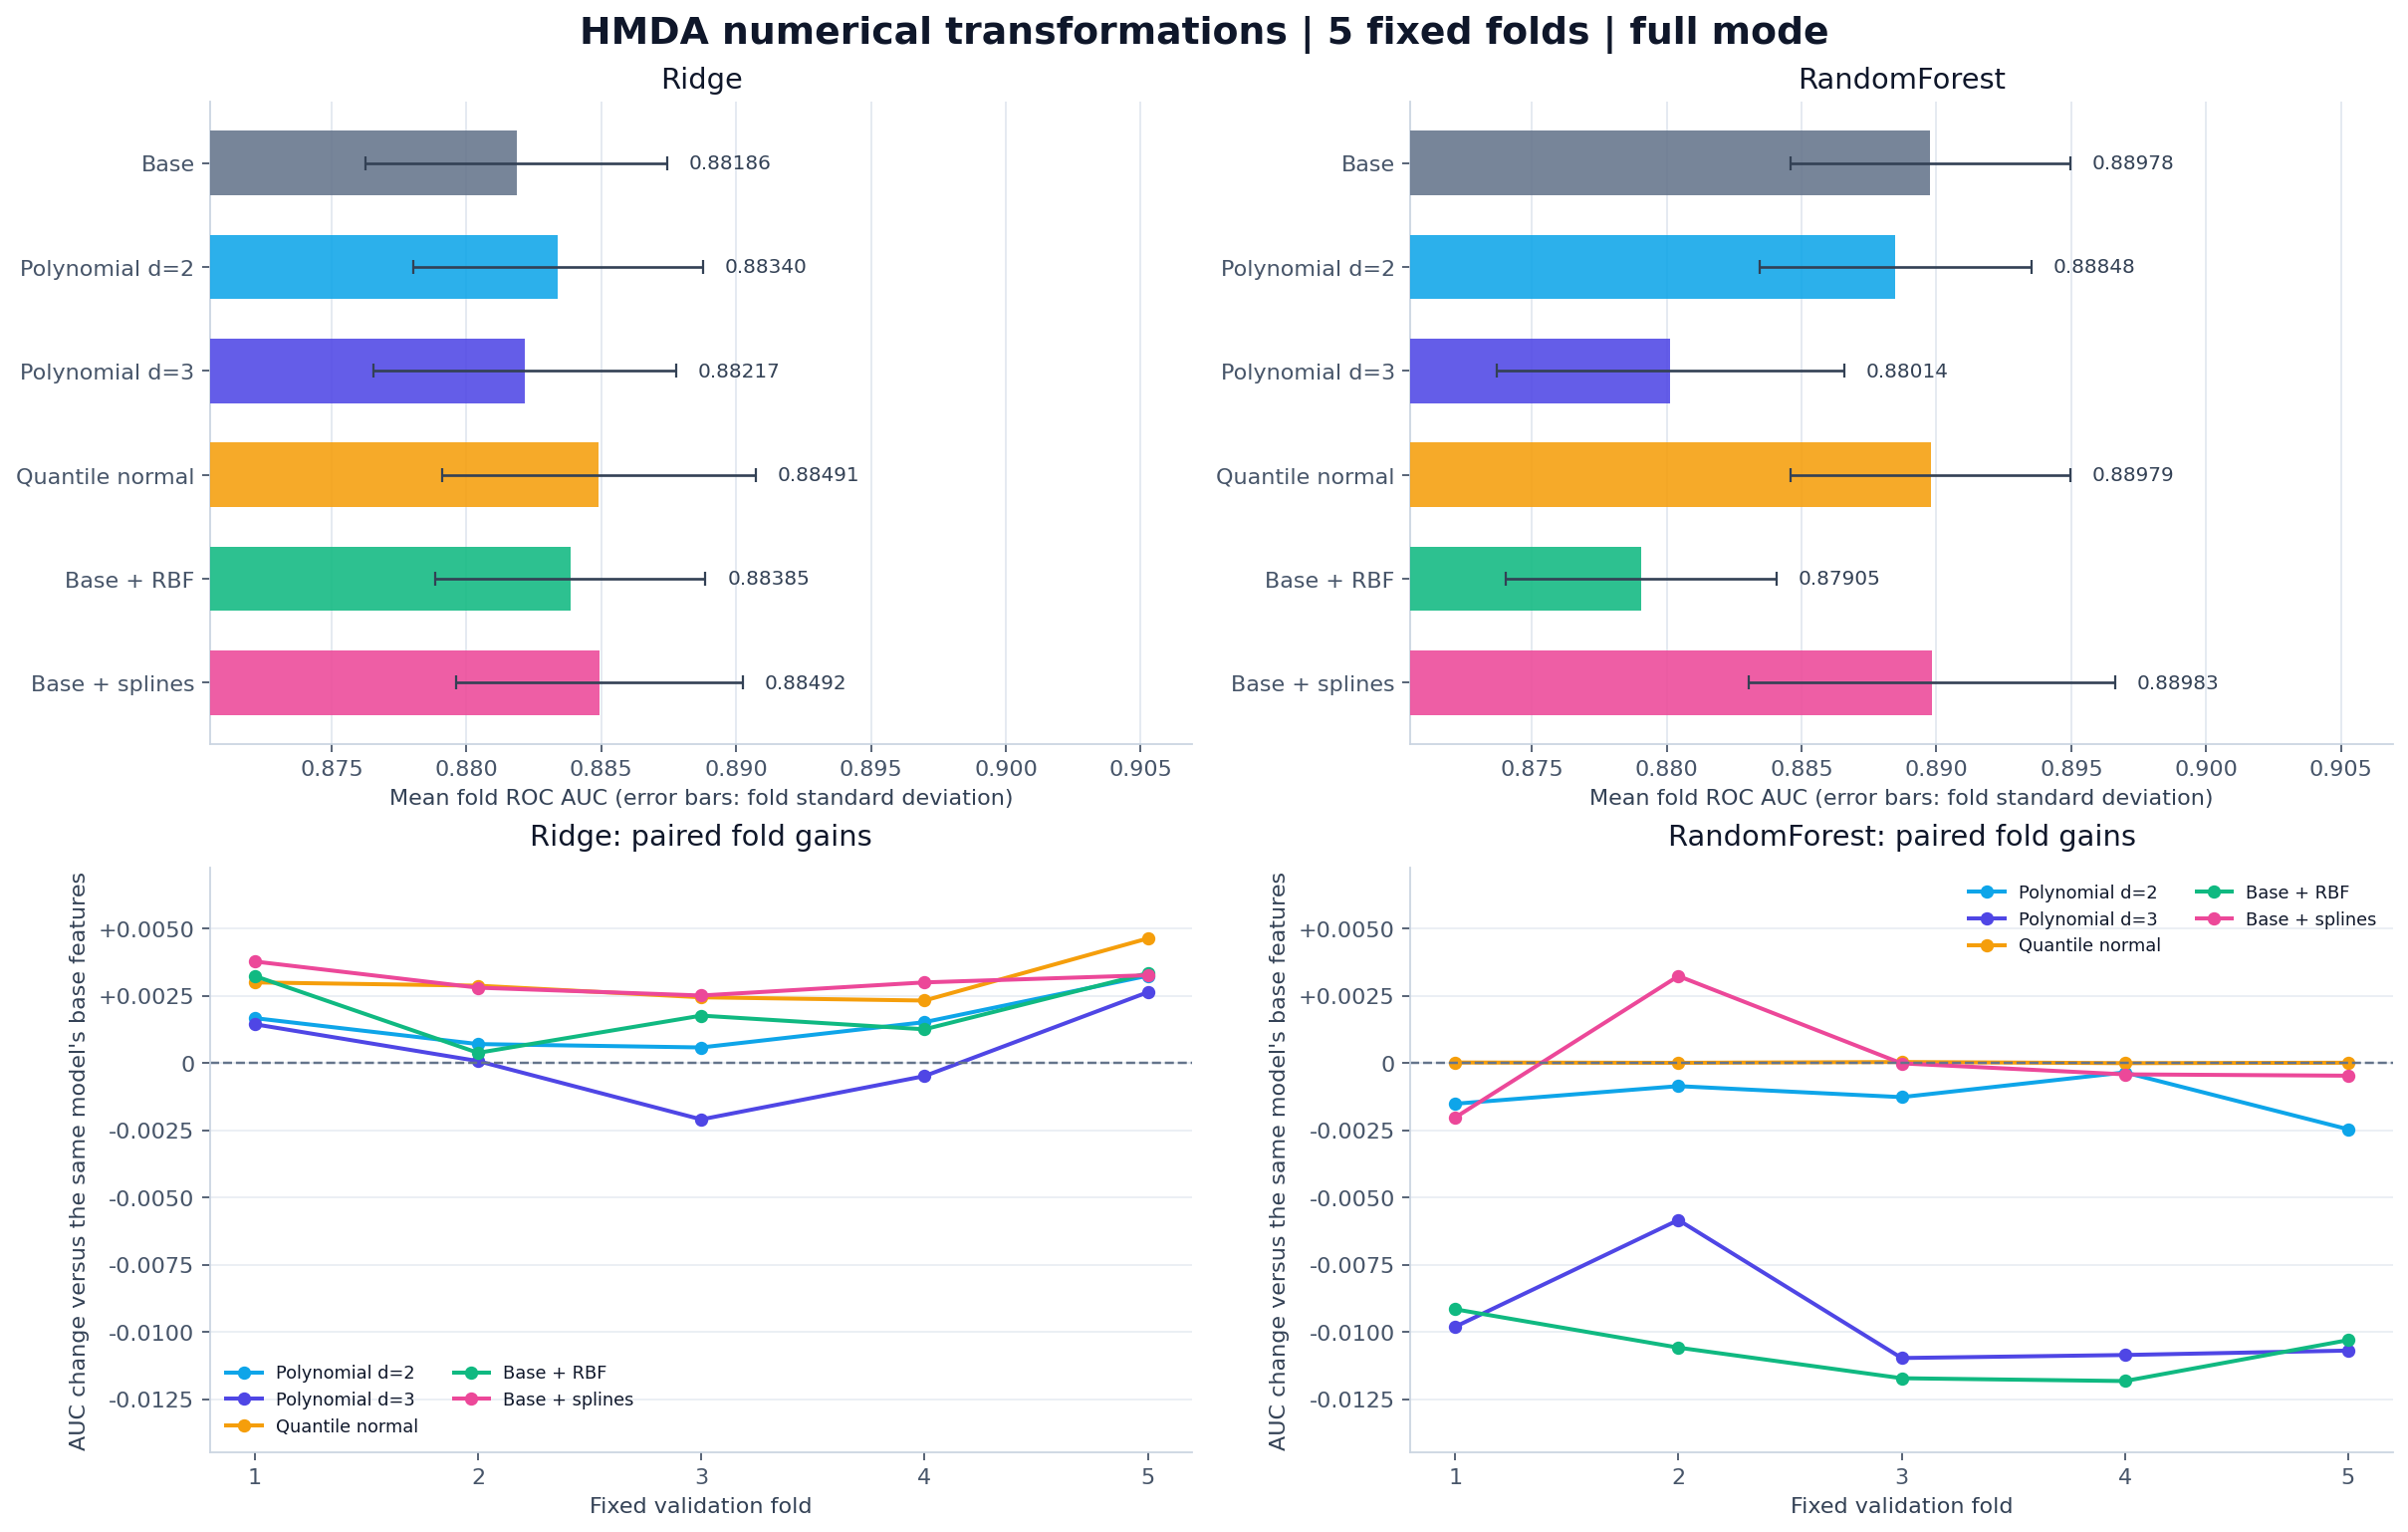

In [9]:
TRANSFORM_DIR = ARTIFACTS / '03_model_selection' / 'transformations'
transform = pd.read_csv(TRANSFORM_DIR / 'auc_summary.csv')
order = ['base', 'poly2', 'poly3', 'quantile', 'rbf', 'spline']
display_named(transform.pivot(index='representation', columns='model', values='auc_mean').reindex(order).round(5))
if (TRANSFORM_DIR / 'auc_comparison.png').is_file():
    display_named(Image(filename=str(TRANSFORM_DIR / 'auc_comparison.png'), width=760))

## 3. Réglage de CatBoost

**Protocole.** Dans chaque pli, 15 % de la partie d'apprentissage sont réservés à l'early stopping, ce qui donne un nombre d'itérations *b*. Le modèle est ensuite réentraîné sur toute la partie d'apprentissage pendant `round(b / 0.85)` itérations, et le pli de validation ne sert qu'au score. La référence est le CatBoost profondeur 8 sur GPU (taux 0.05, 1 600 itérations). Douze réglages sont d'abord triés sur le pli 1, puis les meilleurs sont évalués sur les cinq plis.

In [10]:
EXPERIMENT_ID = 'catboost_tuning'
FOLDS = [1, 2, 3, 4, 5]     # Deuxième série : confirmation sur cinq folds ; [1] pour un tri sur le premier fold
RUN_ONLY = [TUNING_DEPTH8_FIXED1600, TUNING_DEPTH8_BERNOULLI80,
            TUNING_DEPTH8_L2_30_BERNOULLI80, TUNING_DEPTH6_BERNOULLI80]  # None sélectionne tous les candidats
INNER_STOP_FRACTION = 0.15
MAX_ITERATIONS = 10000
OD_WAIT = 300
OUTPUT_DIR = ARTIFACTS / '03_model_selection' / EXPERIMENT_ID

GPU_BASE = dict(
    loss_function='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    allow_writing_files=False, verbose=False,
)
# early_stop=False : nombre d’itérations fixe ; ordre croissant de durée estimée
CANDIDATES = {
    TUNING_DEPTH8_FIXED1600:   dict(depth=8, learning_rate=0.05, l2_leaf_reg=3, early_stop=False, iterations=1600),
    TUNING_DEPTH8_LR005_L2_3: dict(depth=8, learning_rate=0.05, l2_leaf_reg=3),
    TUNING_DEPTH6_LR003_L2_10:  dict(depth=6, learning_rate=0.03, l2_leaf_reg=10),
    TUNING_DEPTH8_LR003_L2_10:  dict(depth=8, learning_rate=0.03, l2_leaf_reg=10),
    TUNING_DEPTH8_LR003_L2_3:   dict(depth=8, learning_rate=0.03, l2_leaf_reg=3),
    TUNING_DEPTH8_LR003_L2_30:  dict(depth=8, learning_rate=0.03, l2_leaf_reg=30),
    TUNING_DEPTH8_BERNOULLI80: dict(depth=8, learning_rate=0.03, l2_leaf_reg=10,
                                   bootstrap_type='Bernoulli', subsample=0.8),
    TUNING_DEPTH8_WITH_DTI: dict(depth=8, learning_rate=0.03, l2_leaf_reg=10, dti=True),
    TUNING_DEPTH10_LR003_L2_10: dict(depth=10, learning_rate=0.03, l2_leaf_reg=10),
    TUNING_DEPTH8_LR002_L2_10:  dict(depth=8, learning_rate=0.02, l2_leaf_reg=10),
    # Deuxième série : combiner les trois meilleurs du fold 1 (sous-échantillonnage, depth 6, L2=30)
    TUNING_DEPTH8_L2_30_BERNOULLI80: dict(depth=8, learning_rate=0.03, l2_leaf_reg=30,
                                    bootstrap_type='Bernoulli', subsample=0.8),
    TUNING_DEPTH6_BERNOULLI80: dict(depth=6, learning_rate=0.03, l2_leaf_reg=10,
                                    bootstrap_type='Bernoulli', subsample=0.8),
}
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(CANDIDATES)
    if unknown:
        raise ValueError(f'Candidats inconnus dans RUN_ONLY : {sorted(unknown)}')

In [11]:
if TRAIN['tuning']:
    ensure_catboost()
    ensure_gpu()
    X_dti = pd.concat([X_base, BLOCKS['dti'][0]], axis=1)   # Bornes DTI utilisées par le candidat avec bornes DTI
    fixed_config(OUTPUT_DIR, {
        'purpose': 'GPU CatBoost screening, inner 15% early stop then outer refit',
        'seed': SEED, 'inner_stop_fraction': INNER_STOP_FRACTION,
        'max_iterations': MAX_ITERATIONS, 'od_wait': OD_WAIT,
        'gpu_base': {k: v for k, v in GPU_BASE.items() if k != 'thread_count'},
        'data_hashes': DATA_HASHES,
    })


    def candidate_params(spec, iterations):
        params = {k: v for k, v in spec.items() if k not in {'early_stop', 'dti', 'iterations'}}
        return dict(GPU_BASE, **params, iterations=iterations)


    def run_one(name, spec, fold):
        features = X_dti if spec.get('dti') else X_base
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        started = time.perf_counter()
        best_iteration = None
        early_stopped = None
        if spec.get('early_stop', True):
            inner_fit, inner_stop = train_test_split(
                fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED,
                stratify=y.iloc[fit_idx],
            )
            probe = catboost.CatBoostClassifier(**candidate_params(spec, MAX_ITERATIONS),
                                                eval_metric='Logloss', od_type='Iter',
                                                od_wait=OD_WAIT, use_best_model=True)
            probe.fit(features.iloc[inner_fit], y.iloc[inner_fit],
                      cat_features=CATEGORICAL_COLUMNS,
                      eval_set=(features.iloc[inner_stop], y.iloc[inner_stop]))
            best_iteration = int(probe.get_best_iteration()) + 1
            early_stopped = int(probe.tree_count_) < MAX_ITERATIONS
            if not early_stopped:
                print(f'  Attention : {name} atteint {MAX_ITERATIONS} itérations sans arrêt anticipé ; résultat potentiellement sous-estimé')
            rounds = int(round(best_iteration / (1 - INNER_STOP_FRACTION)))
            del probe
            gc.collect()
        else:
            rounds = int(spec['iterations'])
        model = catboost.CatBoostClassifier(**candidate_params(spec, rounds), use_best_model=False)
        model.fit(features.iloc[fit_idx], y.iloc[fit_idx], cat_features=CATEGORICAL_COLUMNS)
        require(int(model.tree_count_) == rounds, 'Nombre d’itérations incorrect pour le réentraînement externe')
        probability = checked_probabilities(model, features.iloc[valid_idx])
        actual = y.iloc[valid_idx]
        pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                      'prob': probability}).to_csv(
            OUTPUT_DIR / f'{name}__fold{fold}.csv', index=False, float_format='%.12f')
        result = {
            'candidate': name, 'fold': fold,
            'spec': {k: v for k, v in spec.items()},
            'feature_count': features.shape[1],
            'inner_best_iteration': best_iteration, 'early_stopped': early_stopped, 'refit_rounds': rounds,
            'valid_auc': roc_auc_score(actual, probability),
            'valid_logloss': log_loss(actual, probability, labels=[0, 1]),
            'valid_brier': brier_score_loss(actual, probability),
            'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
            'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        }
        write_json(OUTPUT_DIR / f'{name}__fold{fold}.json', result)
        del model
        gc.collect()
        return result


    def load_results():
        rows = [json.loads(p.read_text(encoding='utf-8'))
                for p in sorted(OUTPUT_DIR.glob('*__fold*.json'))]
        return pd.DataFrame(rows)


    selected = {n: s for n, s in CANDIDATES.items() if RUN_ONLY is None or n in RUN_ONLY}
    for fold in FOLDS:
        for name, spec in selected.items():
            result_path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if result_path.is_file():
                saved = json.loads(result_path.read_text(encoding='utf-8'))
                require(saved['spec'] == spec, f'{name} : définition modifiée ; renommer le candidat')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            result = run_one(name, spec, fold)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  '
                  f'itérations={result["refit_rounds"]}  {result["seconds"]/60:.1f} min', flush=True)

    results = load_results()
    require(not results.empty, 'Aucun résultat terminé')
    auc = results.pivot(index='fold', columns='candidate', values='valid_auc')
    require(TUNING_DEPTH8_FIXED1600 in auc.columns, 'Référence Profondeur 8 · 1 600 itérations fixes manquante')
    delta = auc.sub(auc[TUNING_DEPTH8_FIXED1600], axis=0)
    table = pd.DataFrame({
        'folds_done': auc.notna().sum(),
        'mean_auc': auc.mean(),
        MEAN_GAIN_VS_FIXED_ITERATIONS: delta.mean(),
        FOLDS_BETTER_THAN_FIXED_ITERATIONS: (delta > 0).sum(),
        'mean_refit_rounds': results.groupby('candidate')['refit_rounds'].mean(),
        'mean_logloss': results.groupby('candidate')['valid_logloss'].mean(),
        'total_minutes': results.groupby('candidate')['seconds'].sum() / 60,
    }).sort_values(MEAN_GAIN_VS_FIXED_ITERATIONS, ascending=False)
    table.to_csv(OUTPUT_DIR / 'summary.csv')
    display_named(table.round(6))
    display_named(delta.round(6))
else:
    print("Bloc désactivé (TRAIN['tuning'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['tuning'] = False) ; affichage des résultats enregistrés dans artifacts/.


Étape 1 : sélection sur le fold 1


,AUC fold 1,Écart à la référence à 1 600 itérations,Itérations de réentraînement
candidate,,,
Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8,0.911277,0.002068,4891
Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8,0.910650,0.001441,3800
Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8,0.910596,0.001386,3491
Profondeur 6 · taux 0.03 · L2=10,0.910281,0.001072,6416
Profondeur 8 · taux 0.03 · L2=30,0.910173,0.000964,4096
Profondeur 8 · taux 0.05 · L2=3,0.909676,0.000467,1333
Profondeur 8 · taux 0.03 · L2=10,0.909641,0.000431,3432
Profondeur 8 · taux 0.02 · L2=10,0.909568,0.000359,4771
Profondeur 8 · taux 0.03 · L2=3,0.909566,0.000357,3212


Étape 2 : confirmation des finalistes sur cinq folds


,folds,mean_auc,delta_vs_base,folds_better,keep
candidate,,,,,
Profondeur 8 · taux 0.03 · L2=10 · Bernoulli 0.8,5,0.916515,0.001561,5,True
Profondeur 6 · taux 0.03 · L2=10 · Bernoulli 0.8,5,0.916377,0.001423,5,True
Profondeur 8 · taux 0.03 · L2=30 · Bernoulli 0.8,5,0.916019,0.001065,5,True
Profondeur 8 · 1 600 itérations fixes,5,0.914954,0.000000,0,False


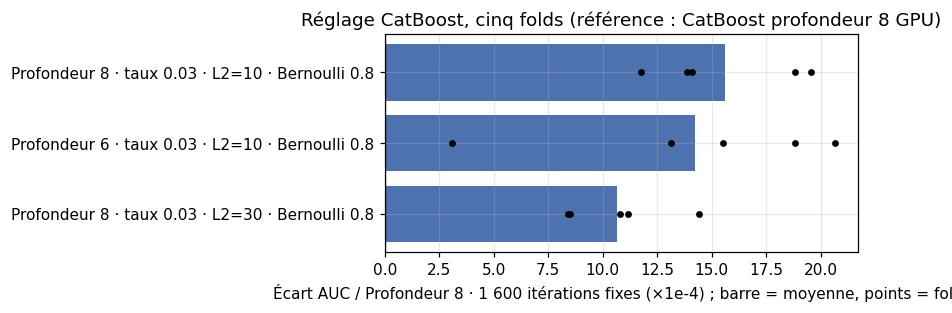

In [12]:
TUNING_DIR = ARTIFACTS / '03_model_selection' / 'catboost_tuning'
tuning_runs = load_runs(TUNING_DIR)
fold1 = tuning_runs[tuning_runs['fold'].eq(1)].set_index('candidate')
screen = pd.DataFrame({
    'AUC fold 1': fold1['valid_auc'],
    'Écart à la référence à 1 600 itérations': fold1['valid_auc'] - fold1.loc[TUNING_DEPTH8_FIXED1600, 'valid_auc'],
    'Itérations de réentraînement': fold1['refit_rounds'],
}).sort_values('AUC fold 1', ascending=False)
print('Étape 1 : sélection sur le fold 1')
display_named(screen.round(6))
finalists = [TUNING_DEPTH8_FIXED1600, TUNING_DEPTH8_BERNOULLI80, TUNING_DEPTH8_L2_30_BERNOULLI80, TUNING_DEPTH6_BERNOULLI80]
table, delta = paired_table(tuning_runs[tuning_runs['candidate'].isin(finalists)], 'candidate', TUNING_DEPTH8_FIXED1600)
print('Étape 2 : confirmation des finalistes sur cinq folds')
display_named(table.round(6))
plot_deltas(delta, TUNING_DEPTH8_FIXED1600, 'Réglage CatBoost, cinq folds (référence : CatBoost profondeur 8 GPU)')

Deux réglages se détachent : **profondeur 8** (taux 0.03, L2 = 10, Bernoulli 0.8), **+0.00156**, et le même en **profondeur 6**, **+0.00142**, tous deux sur les 5 plis. L'échantillonnage Bernoulli explique à lui seul environ 0.001, ce qui confirme l'origine de l'écart CPU/GPU. La profondeur 10 fait moins bien. On garde les deux profondeurs.

## 4. Modes de calcul de CatBoost

Sur le jeu réduit (68 colonnes), on essaie : boosting ordonné, score NewtonL2, croissance Depthwise ou Lossguide, échantillonnage de Poisson, taux d'échantillonnage de 0.66, 254 bins, pas de combinaisons de catégories, et le retrait de colonnes démographiques redondantes. Critère : 0.0005 de gain moyen et 4 plis sur 5.

In [13]:
EXPERIMENT_ID = 'training_modes'
FOLDS = [1, 2, 3, 4, 5]
RUN_ONLY = None                 # Exemple : [TRAINING_STANDARD, TRAINING_ORDERED] ; None sélectionne toutes les variantes
INNER_STOP_FRACTION = 0.15
OUTPUT_DIR = ARTIFACTS / '03_model_selection' / EXPERIMENT_ID

CORE_FEATURE_BLOCKS = ['dti', 'ltv', 'income', 'missing']
REDUCED_FEATURE_BLOCKS = CORE_FEATURE_BLOCKS + ['precision', 'thresholds']        # Les 68 variables de CatBoost profondeur 6 réduit
DEMO_DUPLICATES = [                                 # Codes démographiques et indicateurs d’observation redondants avec derived_*
    'applicant_ethnicity-1', 'co-applicant_ethnicity-1',
    'applicant_race-1', 'co-applicant_race-1',
    'applicant_ethnicity_observed', 'co-applicant_ethnicity_observed',
    'applicant_race_observed', 'co-applicant_race_observed',
    'applicant_sex_observed', 'co-applicant_sex_observed',
]
SCREEN_BASE = dict(              # Proche de CatBoost profondeur 6 réduit (CatBoost profondeur 6), avec un taux d’apprentissage doublé pour le tri ; le jeu externe sert uniquement à évaluer
    depth=6, learning_rate=0.06, l2_leaf_reg=10,
    bootstrap_type='Bernoulli', subsample=0.8,
    loss_function='Logloss', eval_metric='Logloss', nan_mode='Min', random_seed=SEED,
    task_type='GPU', devices='0', thread_count=4,
    iterations=6000, od_type='Iter', od_wait=200, use_best_model=True,
    allow_writing_files=False, verbose=False,
)
VARIANTS = {
    TRAINING_STANDARD: {},
    TRAINING_ORDERED: {'boosting_type': 'Ordered'},            # Sur GPU, Plain est le défaut au-delà de 50 000 lignes ; Ordered reste à tester
    TRAINING_NEWTON_SCORE: {'score_function': 'NewtonL2'},         # Valeur par défaut : Cosine
    TRAINING_DEPTHWISE: {'grow_policy': 'Depthwise', 'depth': 7, 'min_data_in_leaf': 50},
    TRAINING_LOSSGUIDE: {'grow_policy': 'Lossguide', 'depth': 10, 'max_leaves': 48,
                     'min_data_in_leaf': 50, 'score_function': 'NewtonL2'},
    TRAINING_POISSON: {'bootstrap_type': 'Poisson', 'subsample': 0.8},   # Disponible uniquement sur GPU
    TRAINING_ROWS066: {'subsample': 0.66},                      # Sous-échantillonnage des lignes plus marqué
    TRAINING_BINS254: {'border_count': 254},                 # Sur GPU, 128 seuils numériques par défaut
    TRAINING_NO_CATEGORY_COMBINATIONS: {'max_ctr_complexity': 1},                  # Sans combinaison de catégories, pour réduire la variance
    TRAINING_DROP_REDUNDANT_DEMOGRAPHICS: {'drop': DEMO_DUPLICATES},             # Supprimer les 10 colonnes démographiques redondantes
}
if RUN_ONLY is not None:
    unknown = set(RUN_ONLY) - set(VARIANTS)
    if unknown:
        raise ValueError(f'Variantes inconnues dans RUN_ONLY : {sorted(unknown)}')

In [14]:
if TRAIN['screen']:
    ensure_catboost()
    ensure_gpu()
    reduced_train, reduced_test, reduced_cats = variant_frames(REDUCED_FEATURE_BLOCKS)


    def frames_for(spec):
        drop = spec.get('drop', [])
        unknown = set(drop) - set(reduced_train.columns)
        require(not unknown, f'Colonnes à supprimer introuvables : {sorted(unknown)}')
        columns = [c for c in reduced_train.columns if c not in drop]
        return reduced_train[columns], [c for c in reduced_cats if c not in drop]


    def params_for(spec, **extra):
        params = dict(SCREEN_BASE)
        params.update({k: v for k, v in spec.items() if k != 'drop'})
        params.update(extra)
        return params


    # Précontrôle : 20 itérations sur 3 000 lignes par variante pour détecter les paramètres incompatibles avec le GPU
    rng = np.random.default_rng(SEED)
    probe_rows = rng.choice(len(y), 3000, replace=False)
    failed = {}
    for name, spec in VARIANTS.items():
        train, cats = frames_for(spec)
        try:
            model = catboost.CatBoostClassifier(**params_for(spec, iterations=20))
            model.fit(train.iloc[probe_rows[:2500]], y.iloc[probe_rows[:2500]], cat_features=cats,
                      eval_set=(train.iloc[probe_rows[2500:]], y.iloc[probe_rows[2500:]]))
            checked_probabilities(model, train.iloc[probe_rows[2500:]])
            print(f'Précontrôle réussi : {name}({train.shape[1]} colonnes)')
        except Exception as exc:
            failed[name] = repr(exc)
            print(f'Précontrôle échoué, variante ignorée : {name} → {exc!r}')
    require(TRAINING_STANDARD not in failed, 'Échec du précontrôle de Boosting standard ; vérifier l’environnement')

    fixed_config(OUTPUT_DIR, {
        'purpose': PURPOSE_TRAINING_MODES,
        'seed': SEED, 'inner_stop_fraction': INNER_STOP_FRACTION,
        'screen_base': {k: v for k, v in SCREEN_BASE.items() if k != 'thread_count'},
        'features': REDUCED_FEATURE_BLOCKS, 'data_hashes': DATA_HASHES,
    })
    selected = {n: s for n, s in VARIANTS.items()
                if (RUN_ONLY is None or n in RUN_ONLY) and n not in failed}
    for fold in FOLDS:
        fit_idx = np.flatnonzero(fold_assignment != fold)
        valid_idx = np.flatnonzero(fold_assignment == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION,
                                                 random_state=SEED, stratify=y.iloc[fit_idx])
        for name, spec in selected.items():
            path = OUTPUT_DIR / f'{name}__fold{fold}.json'
            if path.is_file():
                saved = json.loads(path.read_text(encoding='utf-8'))
                require(saved['spec'] == spec, f'{name} : définition modifiée ; renommer la variante')
                print(f'{name} fold {fold}: terminé, AUC={saved["valid_auc"]:.6f}, ignoré')
                continue
            train, cats = frames_for(spec)
            started = time.perf_counter()
            model = catboost.CatBoostClassifier(**params_for(spec))
            model.fit(train.iloc[inner_fit], y.iloc[inner_fit], cat_features=cats,
                      eval_set=(train.iloc[inner_stop], y.iloc[inner_stop]))
            best = int(model.get_best_iteration()) + 1
            probability = checked_probabilities(model, train.iloc[valid_idx])
            actual = y.iloc[valid_idx]
            pd.DataFrame({'id': train_ids.iloc[valid_idx].to_numpy(), 'accepted': actual.to_numpy(),
                          'prob': probability}).to_csv(OUTPUT_DIR / f'{name}__fold{fold}__valid.csv',
                                                       index=False, float_format='%.12f')
            result = {'variant': name, 'fold': fold, 'spec': spec, 'feature_count': train.shape[1],
                      'best_iteration': best,
                      'hit_iteration_limit': best >= SCREEN_BASE['iterations'] - SCREEN_BASE['od_wait'],
                      'valid_auc': roc_auc_score(actual, probability),
                      'valid_logloss': log_loss(actual, probability, labels=[0, 1]),
                      'seconds': time.perf_counter() - started, 'gpu_name': GPU_NAME,
                      'finished_at_utc': datetime.now(timezone.utc).isoformat()}
            write_json(path, result)
            print(f'{name} fold {fold}: AUC={result["valid_auc"]:.6f}  meilleures itérations={best}  '
                  f'{result["seconds"]/60:.1f} min', flush=True)
            del model
            gc.collect()

    results = pd.DataFrame([json.loads(p.read_text(encoding='utf-8'))
                            for p in sorted(OUTPUT_DIR.glob('*__fold?.json'))])
    require(not results.empty, 'Aucun résultat terminé')
    auc = results.pivot(index='fold', columns='variant', values='valid_auc')
    require(TRAINING_STANDARD in auc.columns, 'Référence Boosting standard manquante')
    delta = auc.sub(auc[TRAINING_STANDARD], axis=0)
    table = pd.DataFrame({
        'folds_done': auc.notna().sum(),
        'mean_auc': auc.mean(),
        MEAN_GAIN_VS_STANDARD_BOOSTING: delta.mean(),
        FOLDS_BETTER_THAN_STANDARD_BOOSTING: (delta > 0).sum(),
        'mean_best_iteration': results.groupby('variant')['best_iteration'].mean(),
        'total_minutes': results.groupby('variant')['seconds'].sum() / 60,
    })
    table['keep'] = ((table['folds_done'] == 5) & (table[MEAN_GAIN_VS_STANDARD_BOOSTING] >= 0.0005)
                     & (table[FOLDS_BETTER_THAN_STANDARD_BOOSTING] >= 4))
    table.loc[TRAINING_STANDARD, 'keep'] = False
    table = table.sort_values(MEAN_GAIN_VS_STANDARD_BOOSTING, ascending=False)
    table.to_csv(OUTPUT_DIR / 'summary.csv')
    display_named(table.round(6))
    display_named(delta.round(6))
    if failed:
        print('Variantes exclues après échec du précontrôle :', failed)
    kept = table.index[table['keep']].tolist()
    print('Variantes retenues (gain ≥ +0.0005 sur ≥ 4/5 folds) :', kept if kept else 'Aucune')
else:
    print("Bloc désactivé (TRAIN['screen'] = False) ; affichage des résultats enregistrés dans artifacts/.")

Bloc désactivé (TRAIN['screen'] = False) ; affichage des résultats enregistrés dans artifacts/.


,folds,mean_auc,delta_vs_base,folds_better,keep
variant,,,,,
254 seuils numériques,5,0.918895,0.000230,4,False
Boosting standard,5,0.918665,0.000000,0,False
Boosting ordonné,5,0.918636,-0.000029,2,False
Échantillonnage Poisson,5,0.918574,-0.000091,2,False
Échantillonnage des lignes à 0.66,5,0.918464,-0.000202,2,False
Sans colonnes démographiques redondantes,5,0.918443,-0.000222,2,False
Croissance par profondeur,5,0.918121,-0.000544,1,False
Sans combinaison de catégories,5,0.917979,-0.000686,1,False
Score NewtonL2,5,0.917846,-0.000819,0,False


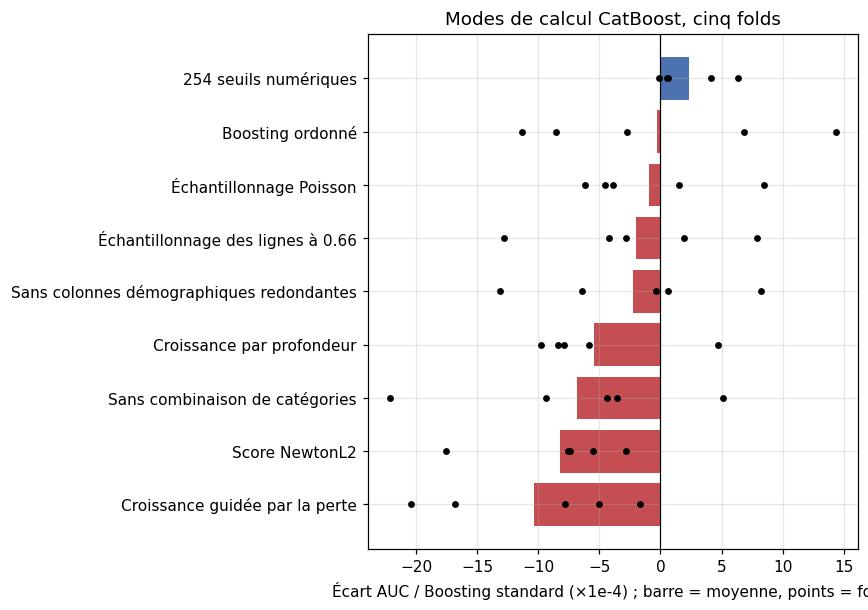

In [15]:
screen_runs = load_runs(ARTIFACTS / '03_model_selection' / 'training_modes')
table, delta = paired_table(screen_runs, 'variant', TRAINING_STANDARD)
display_named(table.round(6))
plot_deltas(delta, TRAINING_STANDARD, 'Modes de calcul CatBoost, cinq folds')

Rien ne passe le critère. Le mieux est 254 bins, avec +0.00023 sur 4 plis. On reste sur le réglage de base : arbres symétriques, boosting Plain, score Cosine, Bernoulli 0.8.

## 5. Bilan

On garde **CatBoost sur GPU, en profondeur 8 et en profondeur 6**. Le notebook 04 les associe aux variables du notebook 02.